# Computer Vision Ödevi — Evdeki Nesnelerin Tespiti (YOLOv8n + COCO)


*  **Görev:** Nesne tespiti
*  **Model:** YOLOv8n
*   **Veri seti:** COCO128 (COCO 2017'nin 128 görsellik alt kümesi)
*   **Uygulama:** Gradio



## 1. Kurulum

In [1]:
!pip install -q ultralytics gradio
import os, random, shutil, time, glob, yaml, torch
from ultralytics import YOLO
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "YOK (CPU)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4


## 2. Veri setini indirme ve train / val / test olarak ayırma (88 / 20 / 20)

In [2]:
os.makedirs("/content/datasets", exist_ok=True)
%cd /content/datasets
!wget -q -nc https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip
!unzip -q -n coco128.zip
%cd /content

SRC = "/content/datasets/coco128"
DST = "/content/datasets/coco128_split"
images = sorted(glob.glob(f"{SRC}/images/train2017/*.jpg"))
random.seed(42)
random.shuffle(images)
splits = {"train": images[:88], "val": images[88:108], "test": images[108:]}

for split, files in splits.items():
    os.makedirs(f"{DST}/images/{split}", exist_ok=True)
    os.makedirs(f"{DST}/labels/{split}", exist_ok=True)
    for img in files:
        shutil.copy(img, f"{DST}/images/{split}/")
        lbl = img.replace("/images/", "/labels/").replace(".jpg", ".txt")
        if os.path.exists(lbl):
            shutil.copy(lbl, f"{DST}/labels/{split}/")
    print(split, len(files), "görsel")

names = YOLO("yolov8n.pt").names  # COCO'nun 80 sınıfı
data_cfg = {"path": DST, "train": "images/train", "val": "images/val", "test": "images/test", "names": names}
with open("/content/data.yaml", "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)
print("Sınıf sayısı:", len(names))

/content/datasets
/content
train 88 görsel
val 20 görsel
test 20 görsel
Sınıf sayısı: 80


## 3. Model eğitimi

Bu bölümde modeli eğitirken kullandığım ayarları ve neden bunları seçtiğimi açıkladım.

| Ayar | Değer |
|---|---|
| Model | YOLOv8n (COCO üzerinde önceden eğitilmiş) |
| Girdi boyutu | 640 × 640 |
| Epoch | 30 |
| Batch size | 16 |
| Optimizer | AdamW, öğrenme oranı = 0.001 |
| Dondurulan katmanlar | İlk 10 katman |
| Aktivasyon / çıkış | Gizli katmanlarda SiLU, çıkışta Sigmoid |
| Loss fonksiyonu | Kutu için CIoU + DFL, sınıf için BCE |

**Neden bu ayarları seçtim?**

- **Model:** YOLO ailesinin en küçük ve en hızlı modeli. Önceden eğitilmiş olduğu için sıfırdan başlamama gerek kalmadı.
- **Girdi boyutu:** YOLOv8'in varsayılan görüntü boyutu. Görseller bu boyuta getirilerek modele veriliyor.
- **Epoch:** Başlangıçta 30 tur seçtim. Ancak grafiklerde eğitim kaybı sürekli düşerken doğrulama kaybı arttı ve doğrulama mAP değeri ilk epoch'lardan sonra düştü. Bu, küçük veri setinde modelin ezberlemeye (overfitting) başladığını gösteriyor. YOLO en iyi doğrulama skorunu veren ağırlıkları (best.pt) kaydettiği için testler bu ağırlıklarla yapıldı.
- **Batch size:** Her adımda 16 görsel işleniyor. Hem belleğe sığıyor hem de eğitimi yavaşlatmıyor.
- **Optimizer:** AdamW, hazır bir modeli ince ayar yaparken kararlı çalışıyor. Küçük öğrenme oranı, modelin önceden öğrendiklerini bozmadan yavaş yavaş uyum sağlamasını sağlıyor.
- **Dondurulan katmanlar:** Bu katmanlar kenar, renk ve şekil gibi temel özellikleri zaten öğrenmiş durumda. Az veriyle eğitirken bunları sabit tutup sadece son katmanları eğittim.
- **Aktivasyon / çıkış:** YOLOv8'in kendi tasarımında bunlar kullanılıyor. Sigmoid, her sınıf için 0 ile 1 arasında bir olasılık veriyor.
- **Loss fonksiyonu:** CIoU ve DFL, tahmin edilen kutunun gerçek kutuya ne kadar yakın olduğunu ölçüyor. BCE ise sınıf tahmininin doğru olup olmadığını ölçüyor.

In [3]:
model = YOLO("yolov8n.pt")
t0 = time.time()
model.train(data="/content/data.yaml", epochs=30, imgsz=640, batch=16,
            optimizer="AdamW", lr0=0.001, freeze=10, seed=42,
            project="/content/runs", name="ev_nesneleri", exist_ok=True)
train_time = time.time() - t0
print(f"Eğitim süresi: {train_time/60:.1f} dakika")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ev_nesneleri, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ad

## 4. Test kümesinde performans (IoU tabanlı mAP, Precision, Recall, F1, tahmin süresi)

In [4]:
best = YOLO("/content/runs/ev_nesneleri/weights/best.pt")
m = best.val(data="/content/data.yaml", split="test", imgsz=640)

P, R = m.box.mp, m.box.mr
F1 = 2 * P * R / (P + R + 1e-9)
print(f"Precision     : {P:.3f}")
print(f"Recall        : {R:.3f}")
print(f"F1-score      : {F1:.3f}")
print(f"mAP@0.5 (IoU≥0.5)     : {m.box.map50:.3f}")
print(f"mAP@0.5:0.95          : {m.box.map:.3f}")
print(f"Tahmin süresi (görsel başına): {m.speed['inference']:.1f} ms  (ön işleme {m.speed['preprocess']:.1f} ms, son işleme {m.speed['postprocess']:.1f} ms)")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1572.6±488.8 MB/s, size: 50.0 KB)
val: Scanning /content/datasets/coco128_split/labels/test... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.9Kit/s 0.0s
val: New cache created: /content/datasets/coco128_split/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.4it/s 0.6s
                   all         20        106      0.595      0.642      0.722       0.57
                person          9         27      0.458       0.63      0.688      0.476
               bicycle          1          2      0.807        0.5      0.638      0.482
                   car          2          4      0.653      0.479       0.46      0.266
            motorcycle          1          2          1      

### Ortalama IoU

IoU (Intersection over Union), modelin çizdiği kutunun gerçek kutuyla ne kadar örtüştüğünü gösteriyor. İki kutunun kesişim alanı, birleşim alanına bölünerek hesaplanıyor. 1'e yaklaştıkça kutu daha doğru yere çizilmiş demek.

Bu hücrede test kümesindeki her gerçek nesneyi, modelin aynı sınıf için çizdiği en iyi örtüşen kutuyla eşleştirdim ve iki ortalama hesapladım:
- **Doğru eşleşmelerde ortalama IoU:** Model nesneyi bulduğunda kutuyu ne kadar doğru yere koyduğunu gösteriyor.
- **Tüm nesnelerde ortalama IoU:** Modelin hiç bulamadığı nesneleri 0 sayıyor, bu yüzden daha katı bir ölçü.

In [5]:
# Test kümesinde ortalama IoU
import numpy as np, torch
from PIL import Image as PILImage
from ultralytics.utils.metrics import box_iou

def load_gt(img_path):
    lbl = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    if not os.path.exists(lbl):
        return np.zeros((0,)), np.zeros((0, 4))
    w, h = PILImage.open(img_path).size
    a = np.loadtxt(lbl, ndmin=2)
    cls, xc, yc, bw, bh = a[:, 0], a[:, 1] * w, a[:, 2] * h, a[:, 3] * w, a[:, 4] * h
    return cls, np.stack([xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2], 1)

all_ious, matched_ious = [], []
for img in sorted(glob.glob(f"{DST}/images/test/*.jpg")):
    g_cls, g_box = load_gt(img)
    r = best.predict(img, conf=0.25, imgsz=640, verbose=False)[0]
    p_cls, p_box = r.boxes.cls.cpu().numpy(), r.boxes.xyxy.cpu().numpy()
    used = set()
    for c, gb in zip(g_cls, g_box):
        best_iou, best_j = 0.0, None
        for j, (pc, pb) in enumerate(zip(p_cls, p_box)):
            if j in used or pc != c:
                continue
            iou = float(box_iou(torch.tensor(gb[None]), torch.tensor(pb[None]))[0, 0])
            if iou > best_iou:
                best_iou, best_j = iou, j
        if best_j is not None and best_iou >= 0.5:
            used.add(best_j)
            matched_ious.append(best_iou)
            all_ious.append(best_iou)
        else:
            all_ious.append(0.0)  # kaçırılan ya da yanlış konumlanan nesne

mean_iou_matched = float(np.mean(matched_ious)) if matched_ious else 0.0
mean_iou_all = float(np.mean(all_ious)) if all_ious else 0.0
print(f"Gerçek kutu sayısı           : {len(all_ious)}")
print(f"Doğru eşleşen (IoU ≥ 0.5)    : {len(matched_ious)}")
print(f"Ortalama IoU (doğru eşleşmeler): {mean_iou_matched:.3f}  → kutuların konum hassasiyeti")
print(f"Ortalama IoU (tüm nesneler, kaçırılan = 0): {mean_iou_all:.3f}")

Gerçek kutu sayısı           : 106
Doğru eşleşen (IoU ≥ 0.5)    : 56
Ortalama IoU (doğru eşleşmeler): 0.854  → kutuların konum hassasiyeti
Ortalama IoU (tüm nesneler, kaçırılan = 0): 0.451


results.png


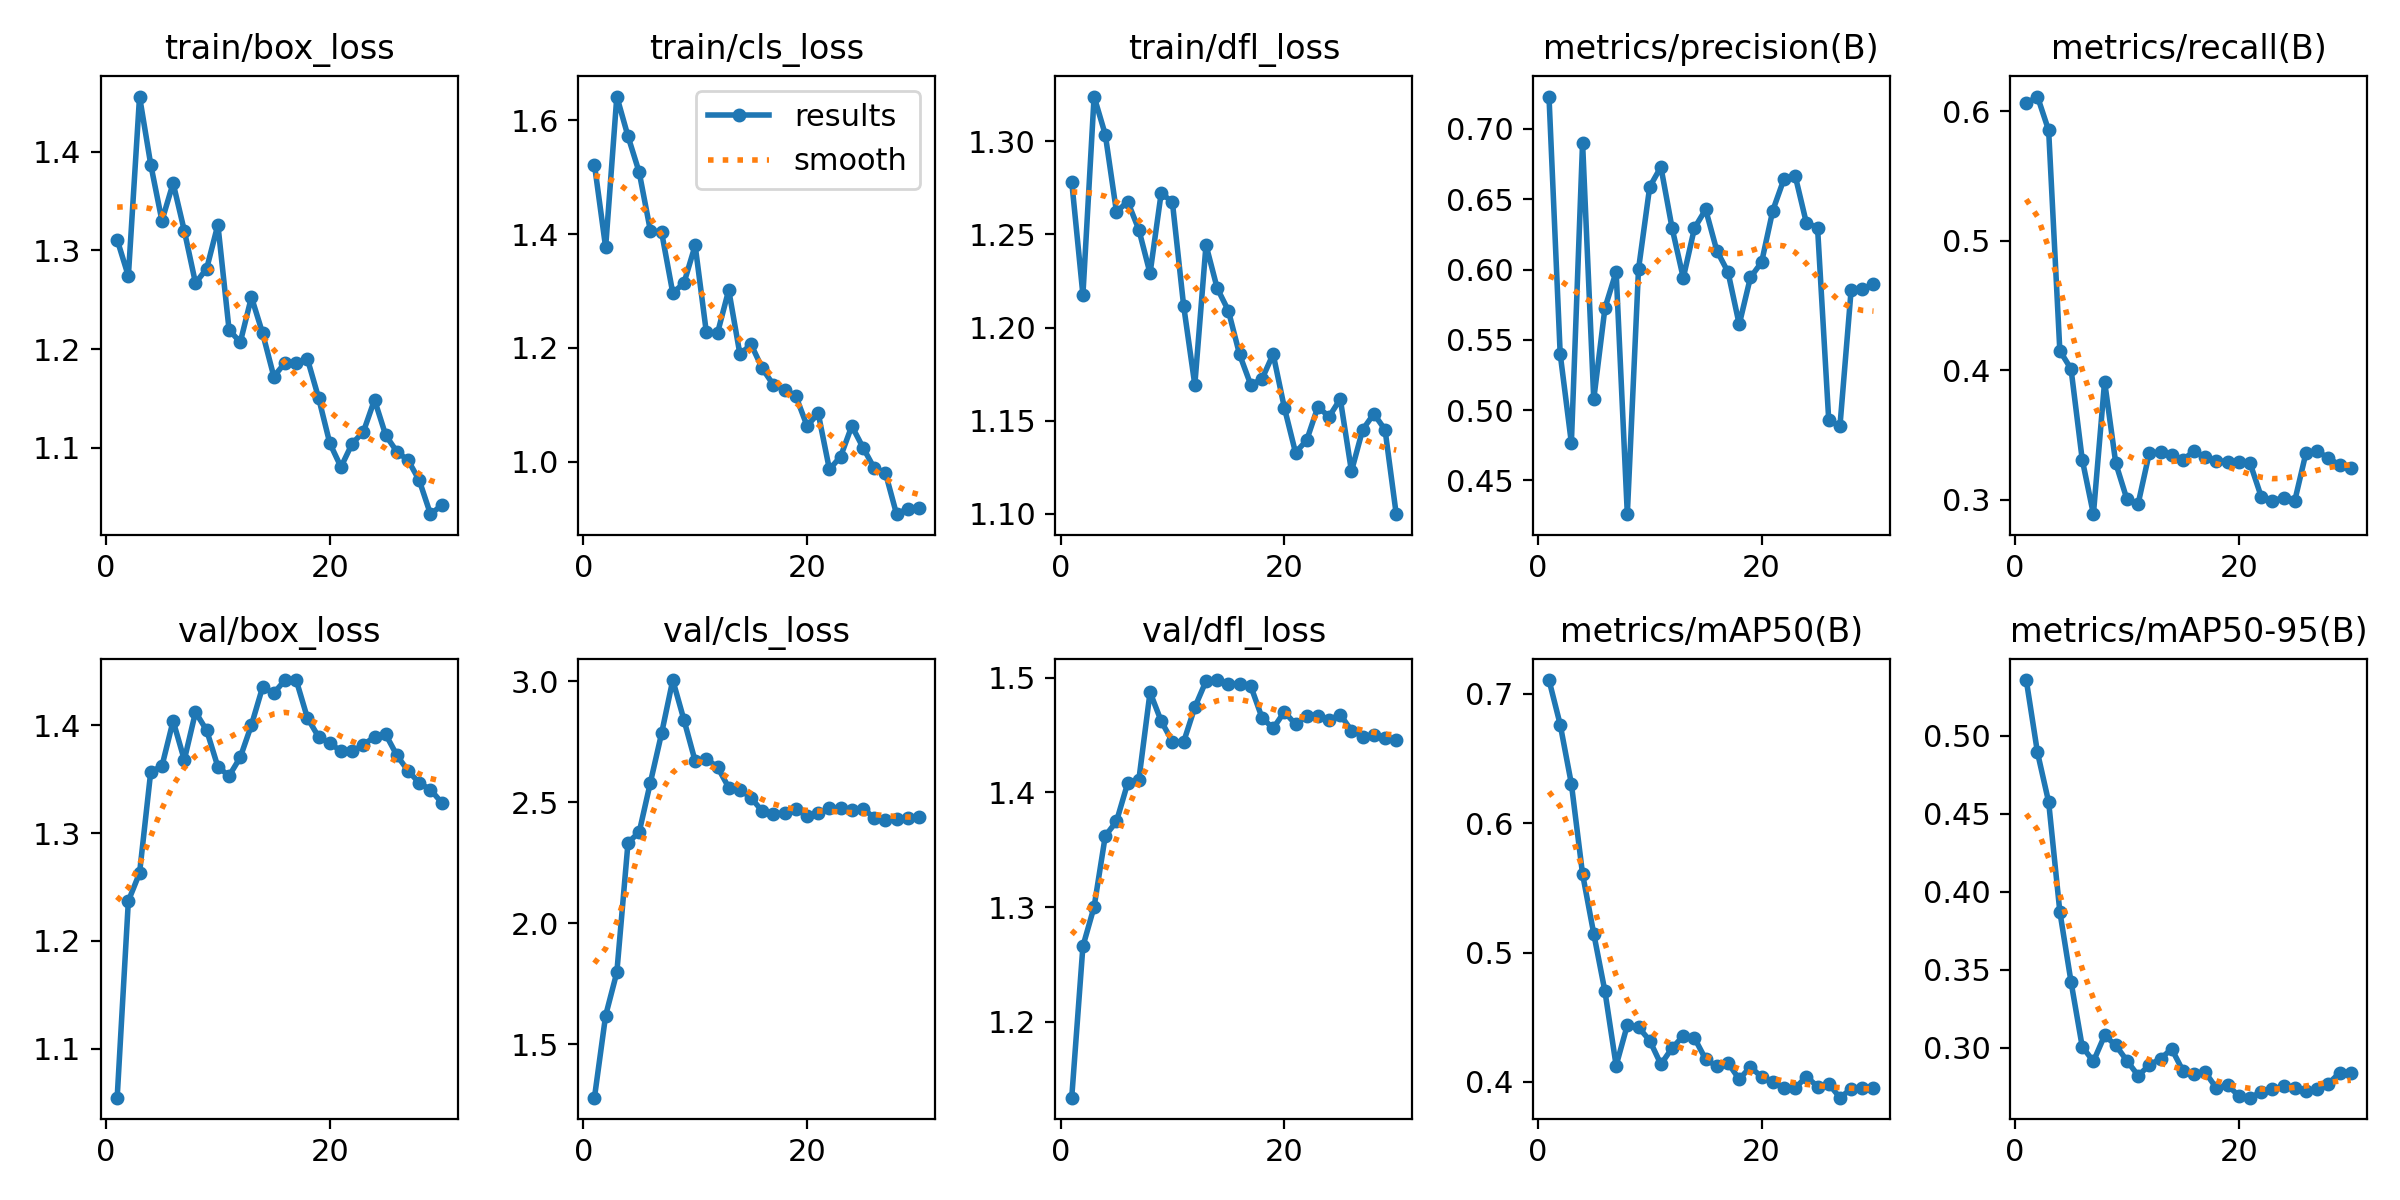

confusion_matrix.png


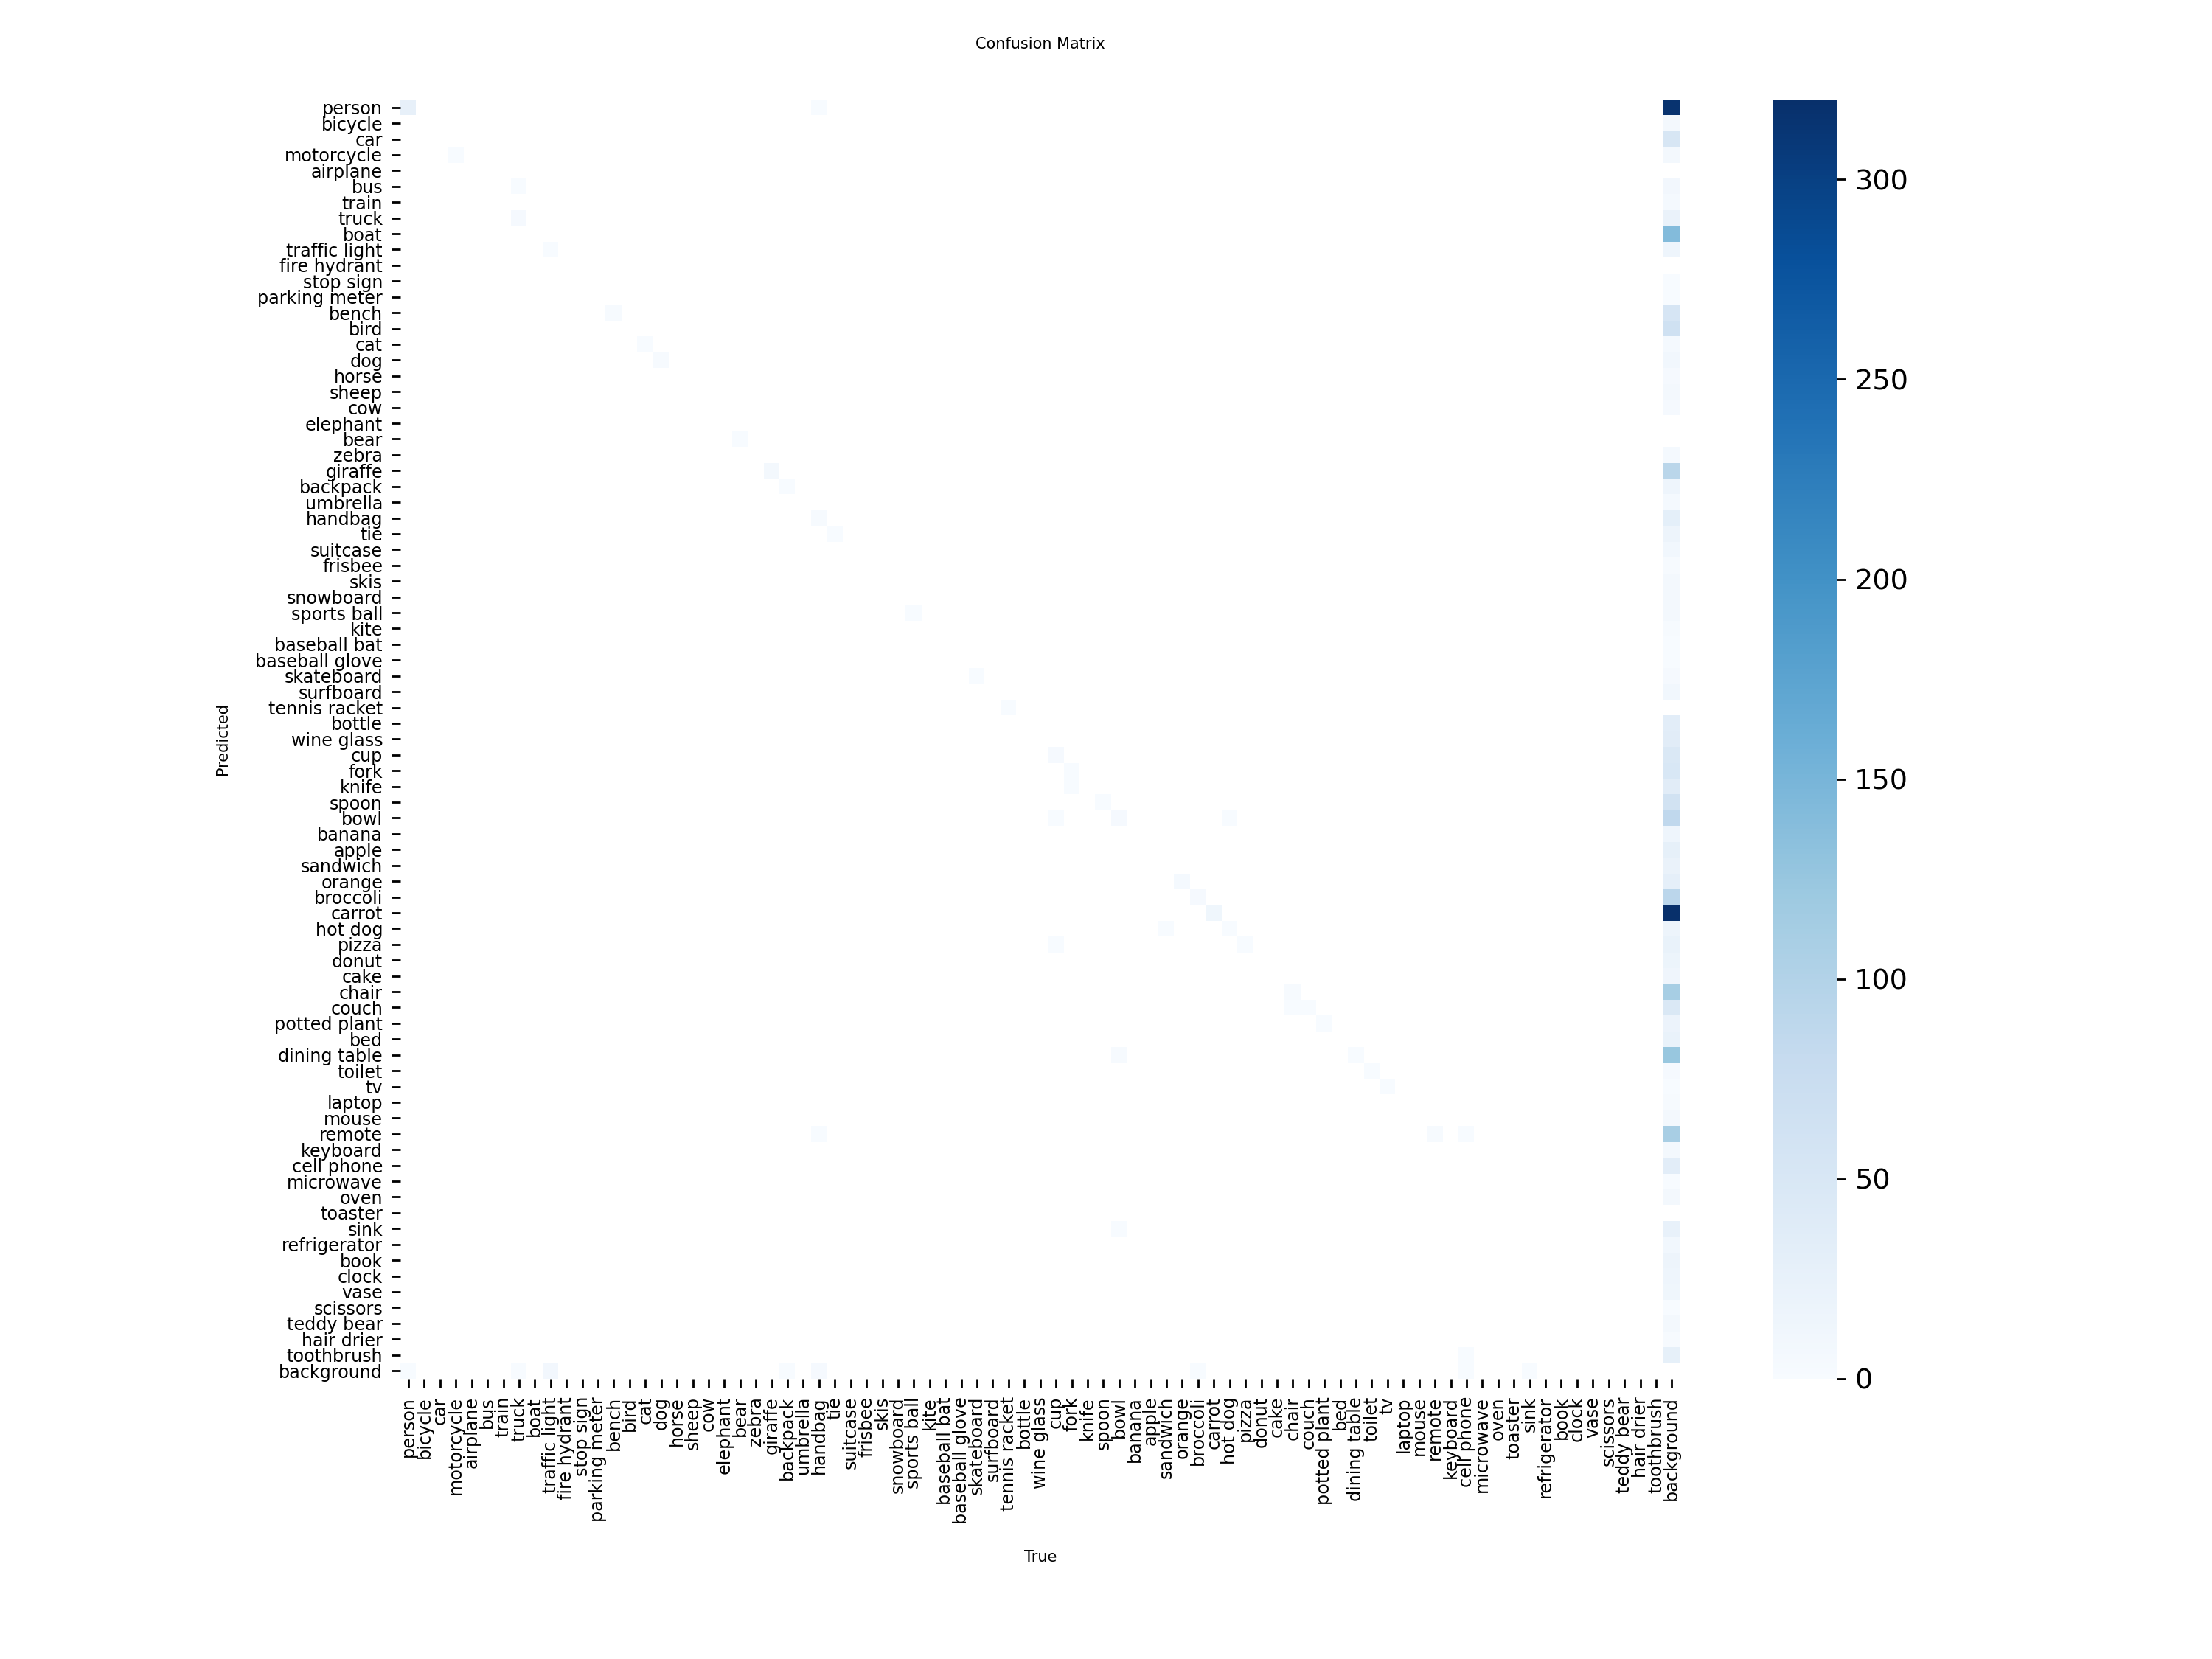

In [6]:
from IPython.display import Image, display
for f in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    p = f"/content/runs/ev_nesneleri/{f}"
    if os.path.exists(p):
        print(f); display(Image(p, width=800))

# 5. Kendi çektiğim 5 fotoğrafla test

Modeli gerçek hayatta denemek için telefonumla evde 5 farklı fotoğraf çektim. Fotoğrafları bilerek çeşitli seçtim:
- Modelin tanıması beklenen nesneler: laptop, mouse, telefon, kitap, makas, diş fırçası, muz, kupa, kaşık
- Zorlayıcı durumlar: üst üste duran ve loş ışıkta çekilmiş nesneler
- Modelin eğitildiği 80 sınıf arasında olmayan nesneler: zımba ve kalem

Böylece modelin hem başarılı olduğu hem de zorlandığı durumları görebildim. Aşağıdaki hücrede fotoğrafları yükleyip modelin tahminlerini inceledim.

Saving WhatsApp Image 2026-11-25 at 20.36.44.jpeg to WhatsApp Image 2026-11-25 at 20.36.44.jpeg
Saving WhatsApp Image 2026-11-25 at 20.36.26 (1).jpeg to WhatsApp Image 2026-11-25 at 20.36.26 (1).jpeg
Saving WhatsApp Image 2026-11-25 at 20.36.26 (2).jpeg to WhatsApp Image 2026-11-25 at 20.36.26 (2).jpeg
Saving WhatsApp Image 2026-11-25 at 20.36.26.jpeg to WhatsApp Image 2026-11-25 at 20.36.26.jpeg
Saving WhatsApp Image 2026-11-25 at 20.36.27.jpeg to WhatsApp Image 2026-11-25 at 20.36.27.jpeg

image 1/5 /content/benim_fotolarim/WhatsApp Image 2026-11-25 at 20.36.26 (1).jpeg: 640x480 1 knife, 1 banana, 1 dining table, 28.8ms
image 2/5 /content/benim_fotolarim/WhatsApp Image 2026-11-25 at 20.36.26 (2).jpeg: 640x480 1 laptop, 1 mouse, 1 cell phone, 22.6ms
image 3/5 /content/benim_fotolarim/WhatsApp Image 2026-11-25 at 20.36.26.jpeg: 640x480 1 banana, 21.2ms
image 4/5 /content/benim_fotolarim/WhatsApp Image 2026-11-25 at 20.36.27.jpeg: 640x480 1 cup, 1 spoon, 1 banana, 19.4ms
image 5/5 /cont

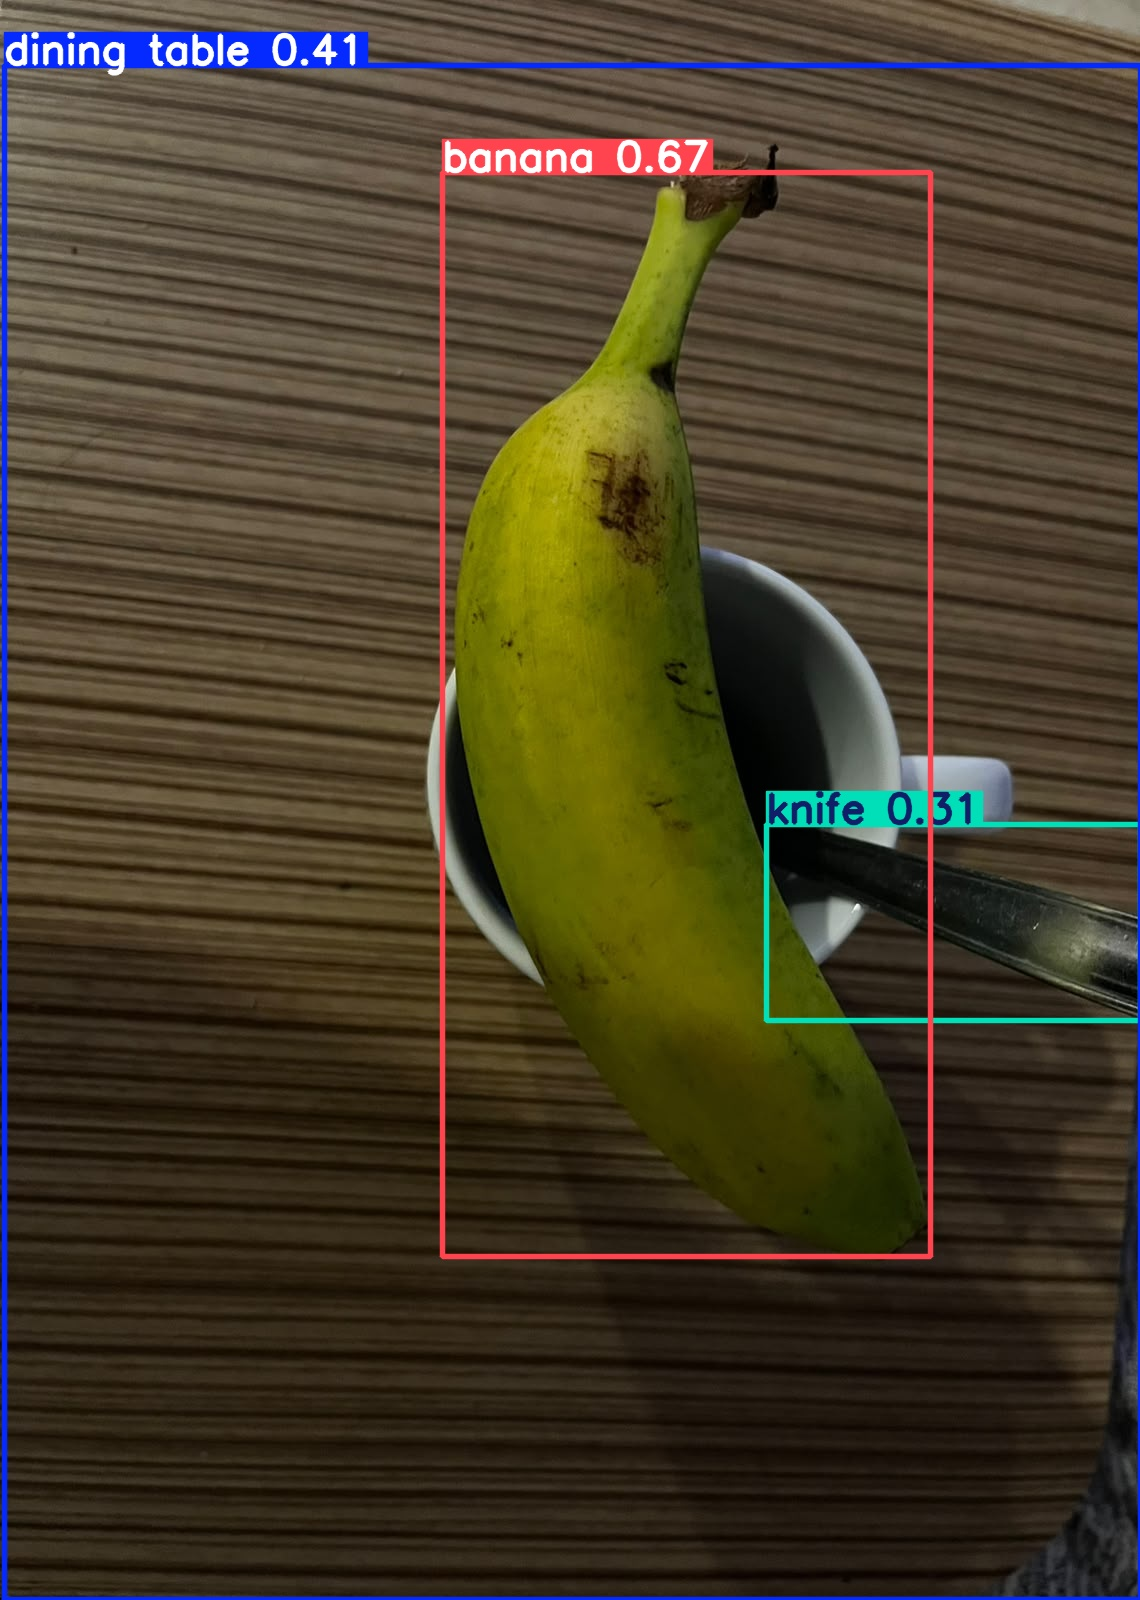

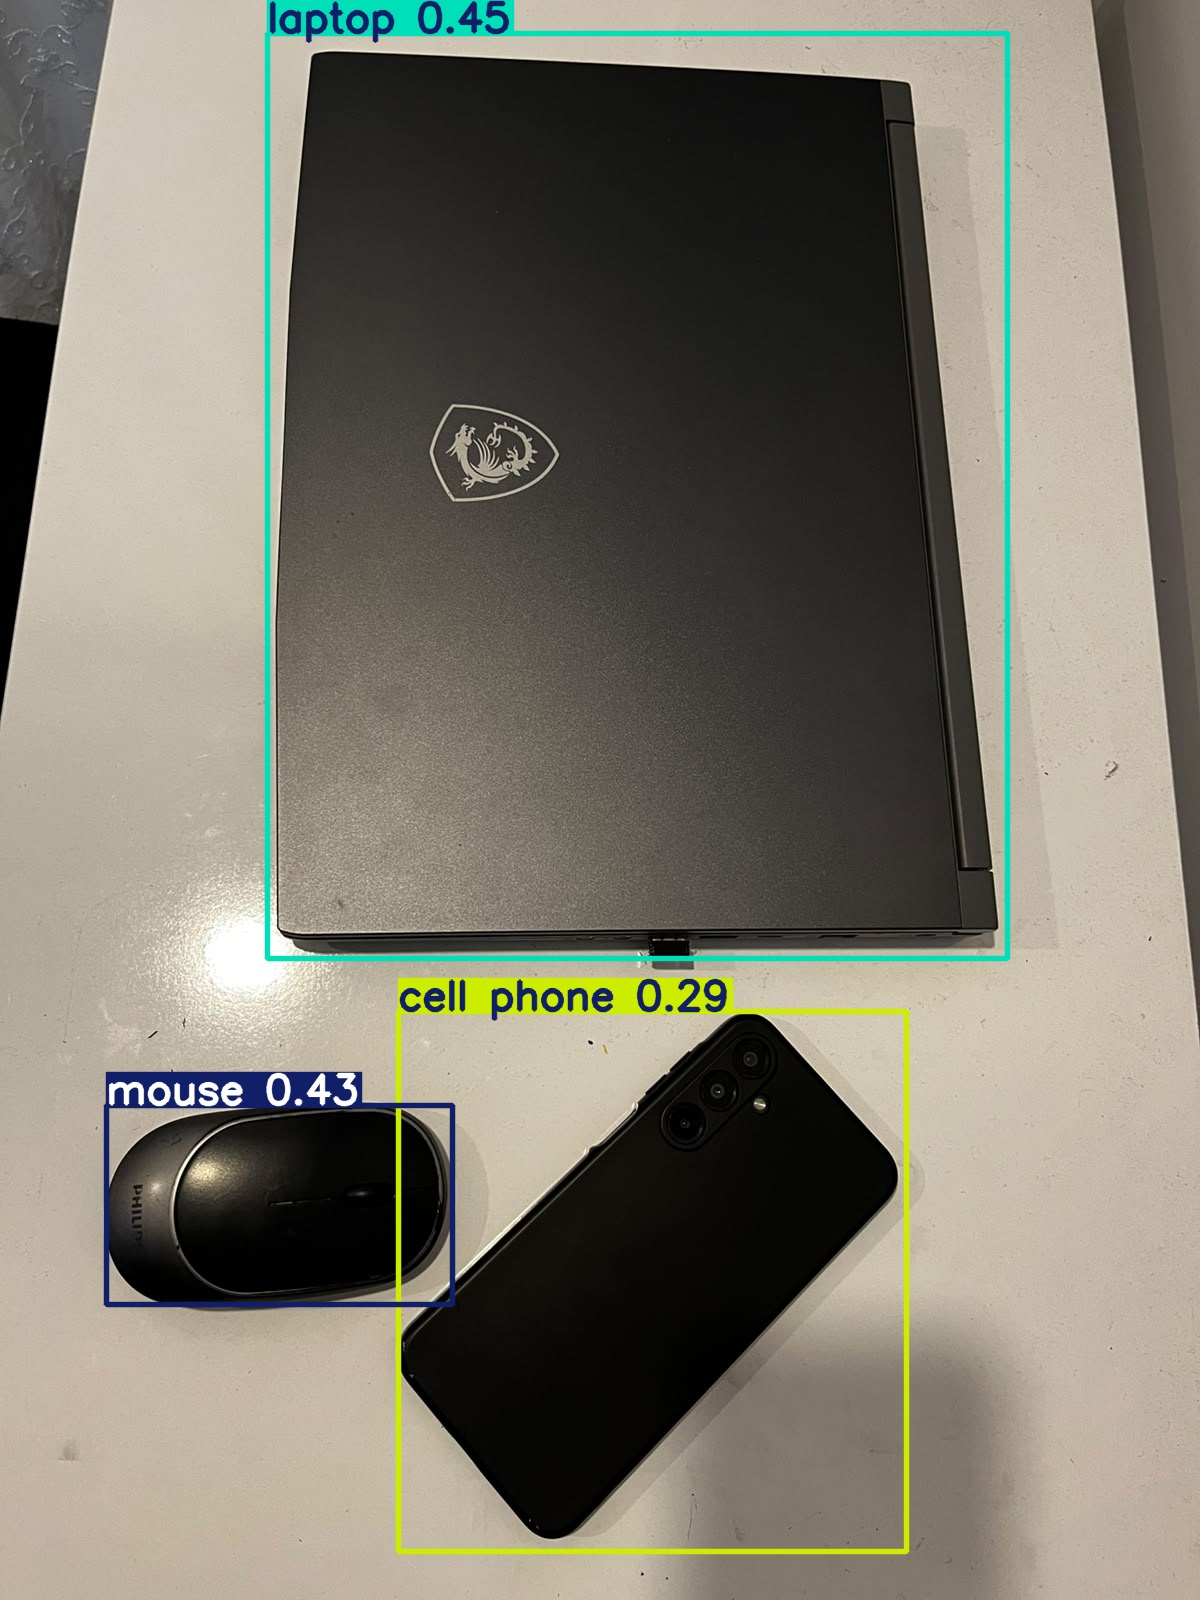

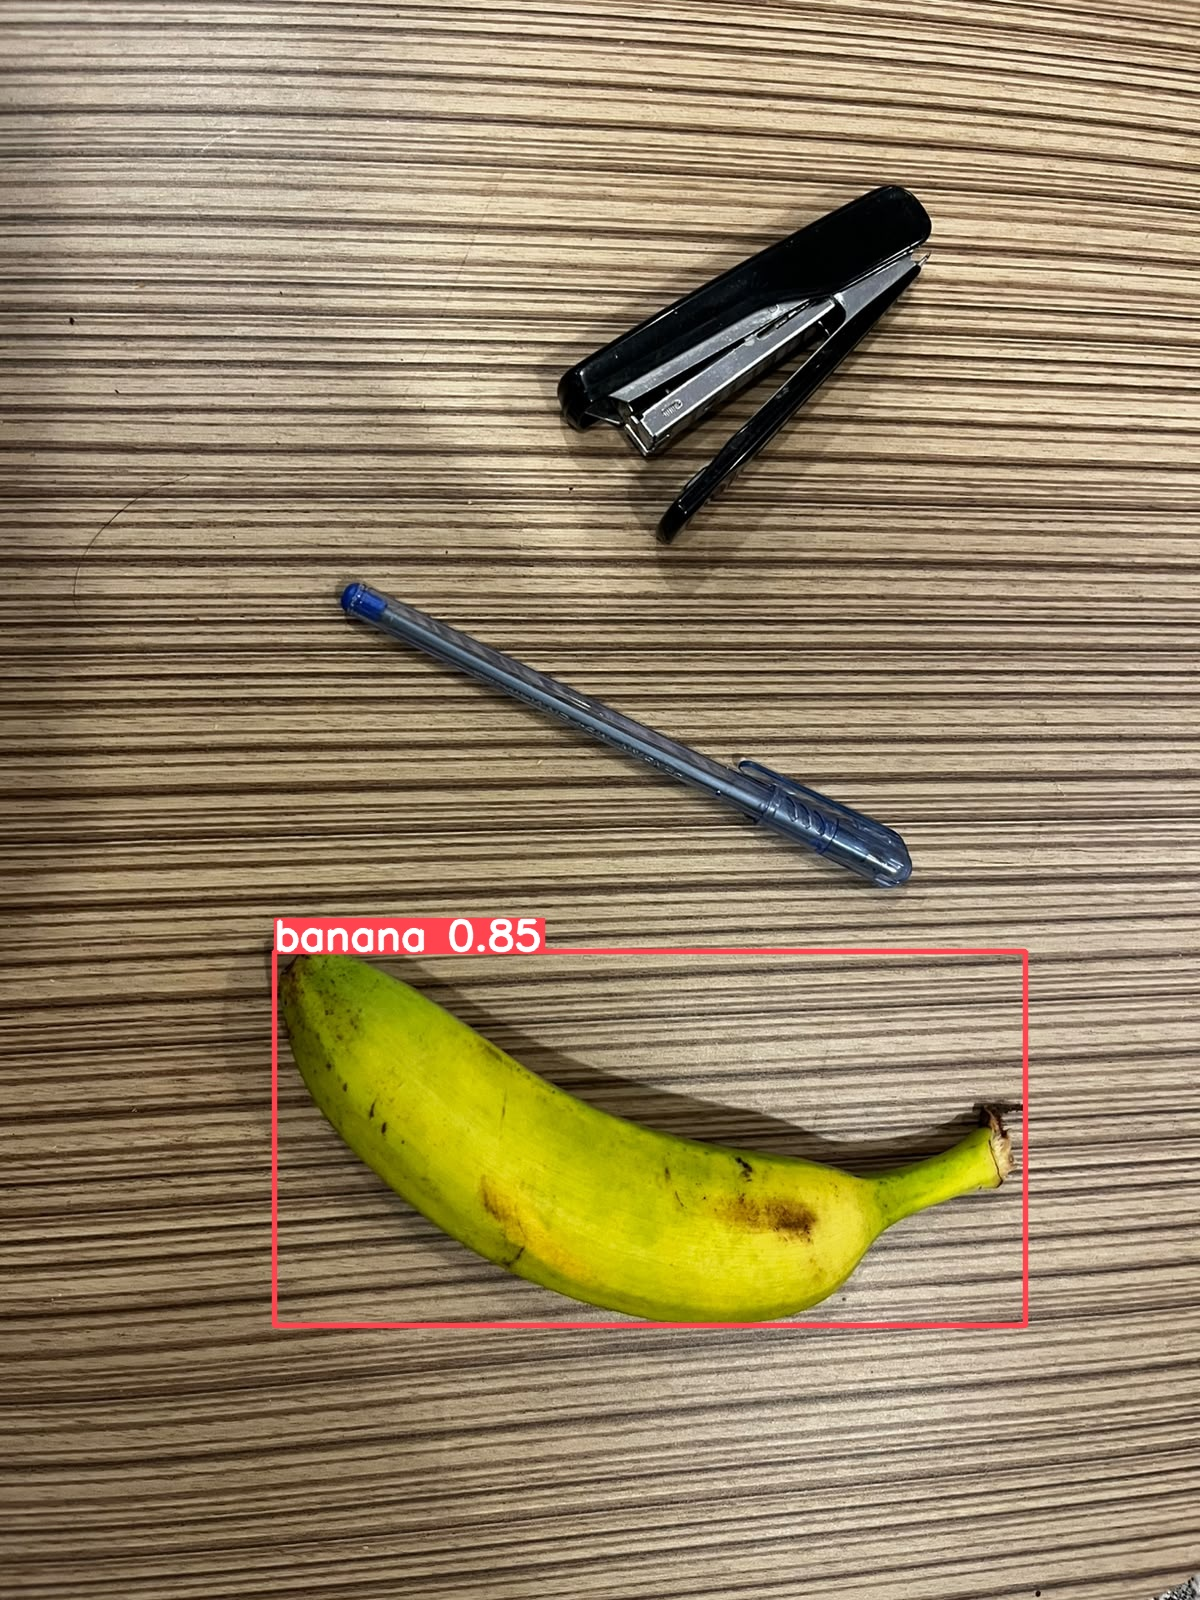

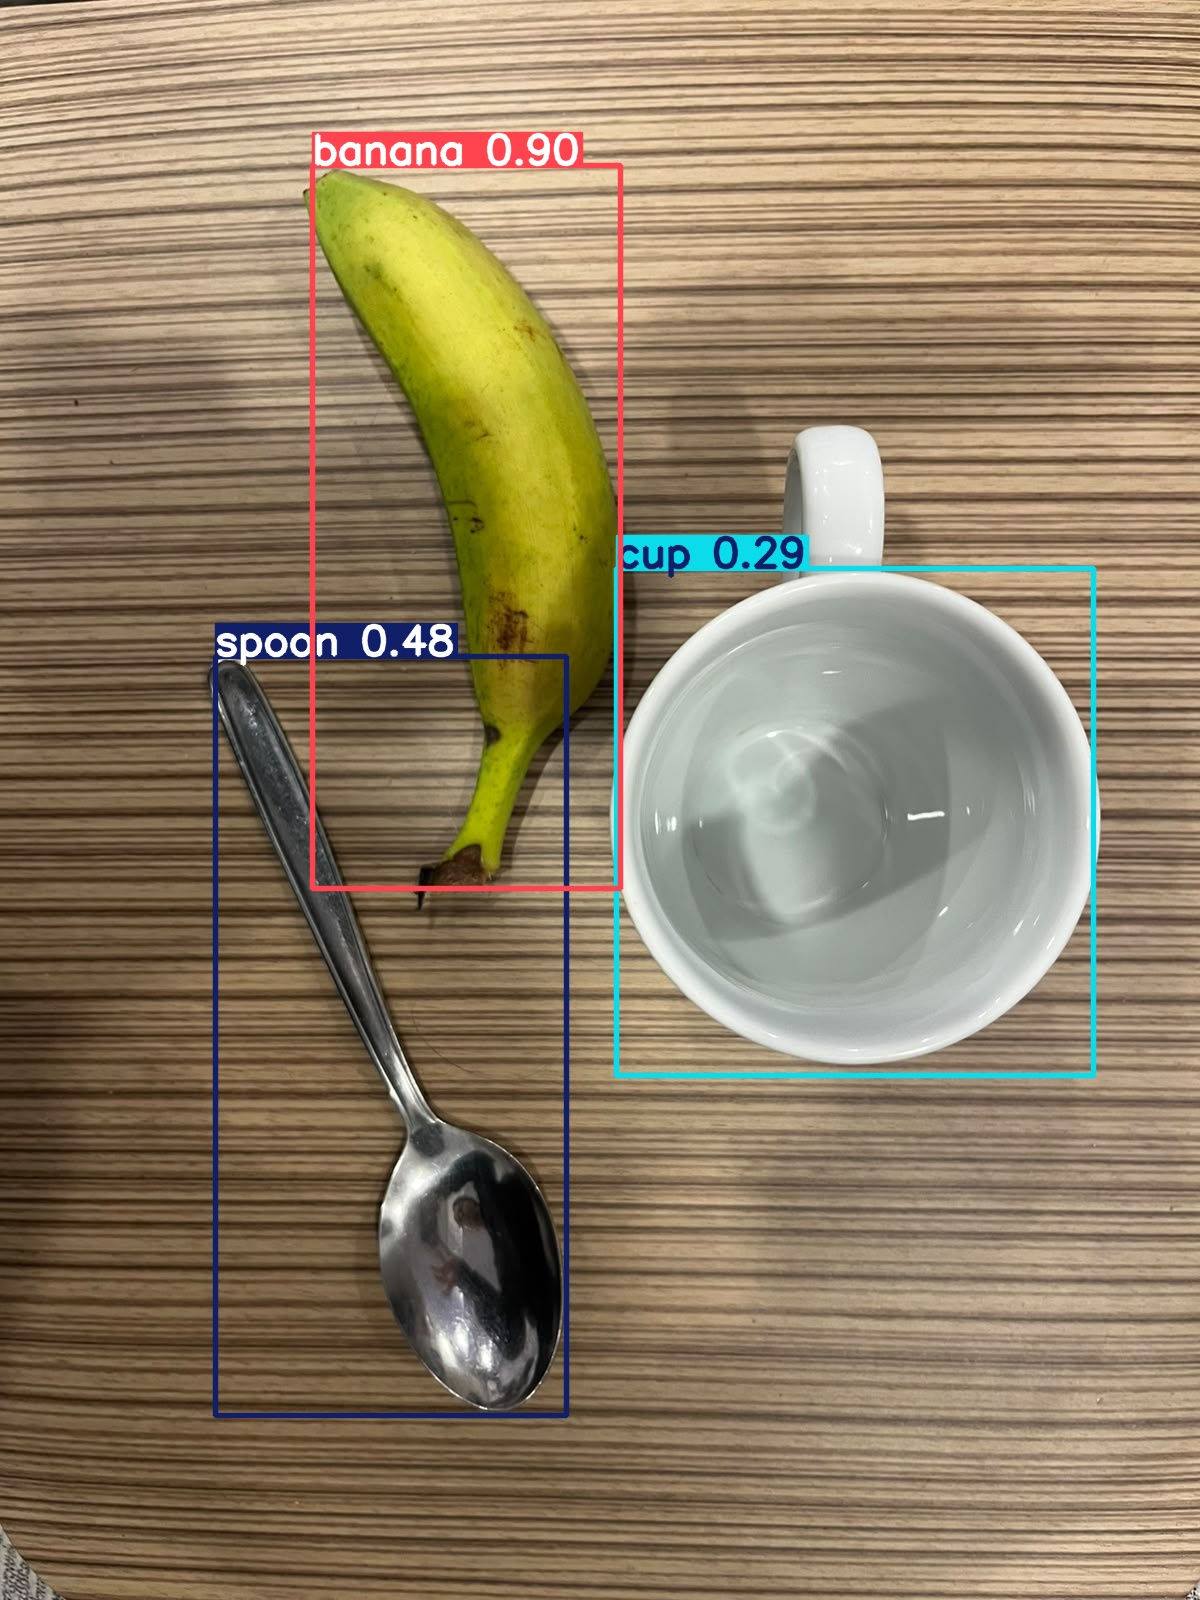

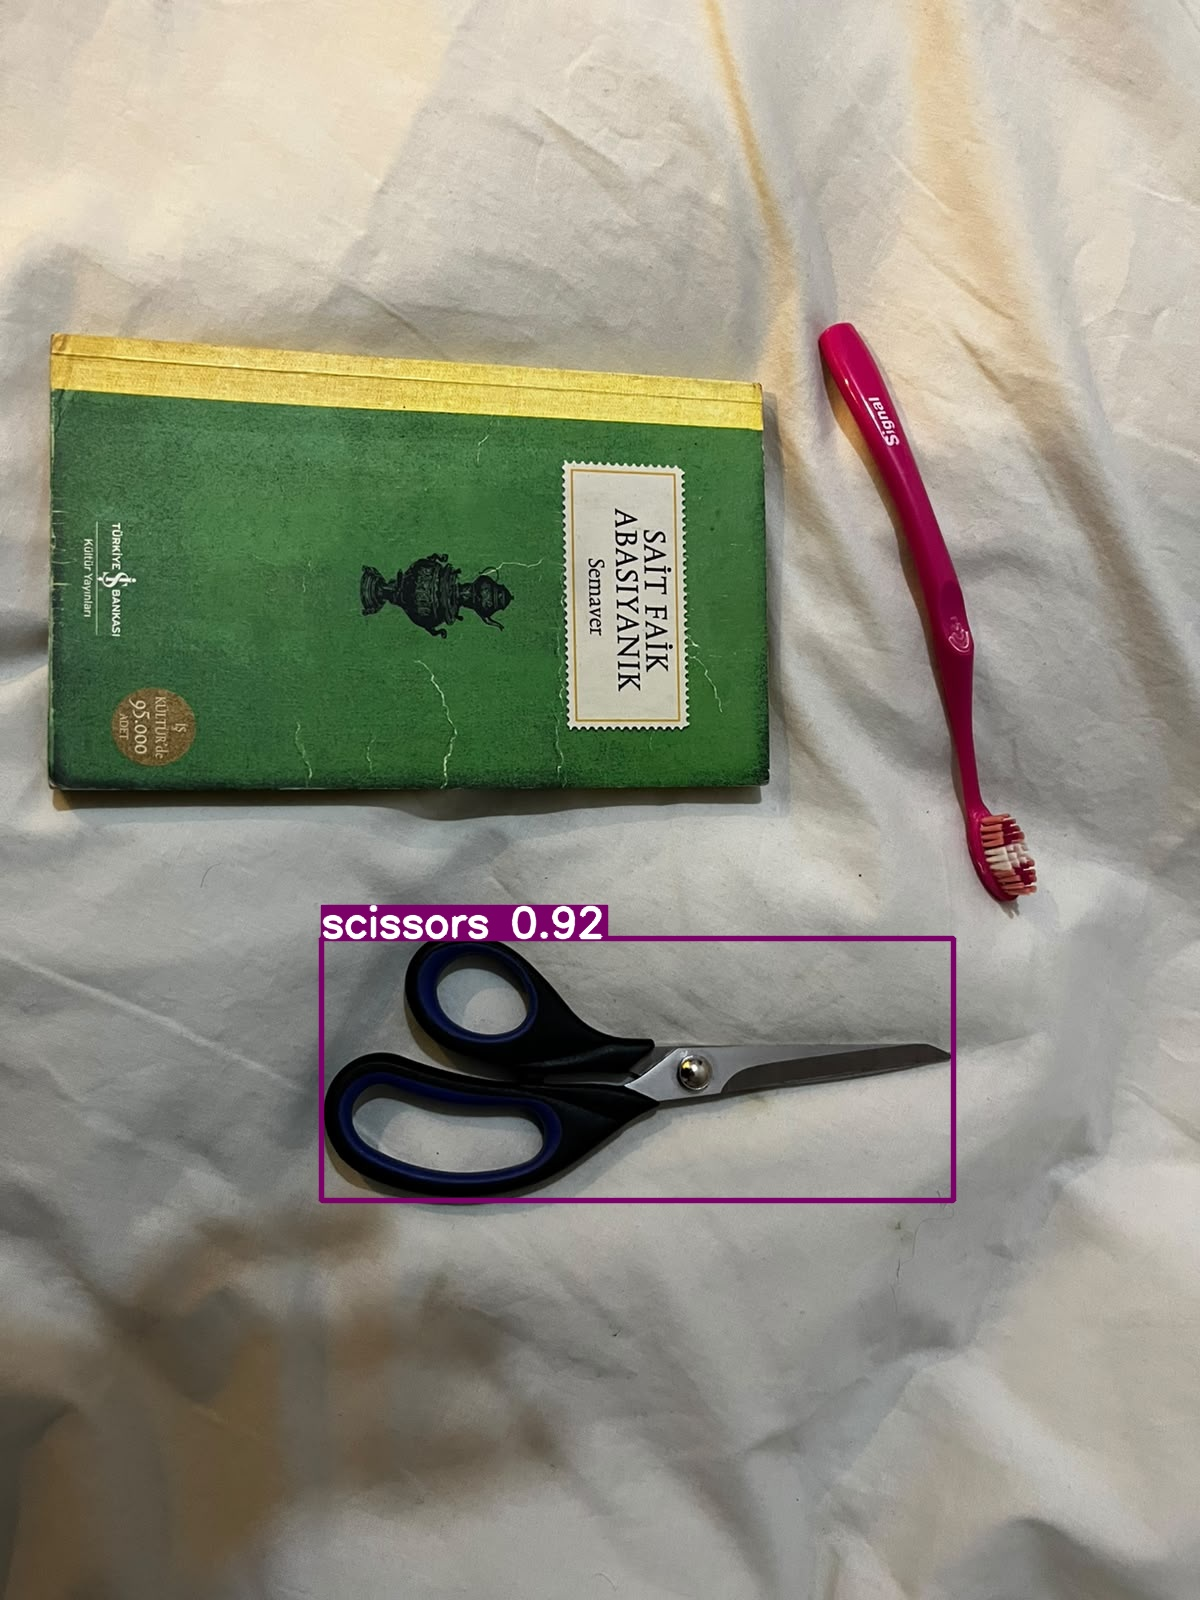

In [7]:
from google.colab import files
uploaded = files.upload()
os.makedirs("/content/benim_fotolarim", exist_ok=True)
for name in uploaded:
    shutil.move(name, f"/content/benim_fotolarim/{name}")

results = best.predict("/content/benim_fotolarim", conf=0.25, save=True,
                       project="/content/runs", name="benim_tahminlerim", exist_ok=True)
for r in results:
    print("\n", os.path.basename(r.path), f"— {r.speed['inference']:.1f} ms")
    for b in r.boxes:
        print(f"   {best.names[int(b.cls)]:<15} güven: {float(b.conf):.2f}")
for p in sorted(glob.glob("/content/runs/benim_tahminlerim/*")):
    display(Image(p, width=600))

**Karşılaştırma tablosu**

| Foto | Gerçekte olanlar | Modelin buldukları | Sonuç | Kısa yorum |
|---|---|---|---|---|
| 1 | Laptop, mouse, telefon | laptop 0.45, mouse 0.43, cell phone 0.29 | ✅ 3/3 | Hepsi doğru, güven düşük |
| 2 | Zımba, kalem, muz | banana 0.85 | ⚠️ 1/3 | Zımba ve kalem COCO'da yok |
| 3 | Kitap, makas, diş fırçası | scissors 0.92 | ⚠️ 1/3 | Kitap ve fırça kaçırıldı |
| 4 | Muz, kupa, kaşık (üst üste, loş) | banana 0.67, dining table 0.41, knife 0.31 | ❌ 1/3 | Kupa kaçırıldı, kaşık bıçak sanıldı |
| 5 | Muz, kupa, kaşık (ayrık, aydınlık) | banana 0.90, spoon 0.48, cup 0.29 | ✅ 3/3 | Hepsi doğru |

**Fotoğraf yorumları**

**Foto 1:** Üç nesneyi de doğru buldu ve kutular nesnelerin üstüne iyi oturdu. Güven skorlarının düşük olmasının nedeni, laptop'un kapağının kapalı olması ve fotoğrafın tepeden çekilmesi. Eğitim verisindeki laptoplar genelde açık ve yandan görünüyor.

**Foto 2:** Muzu yüksek güvenle buldu. Zımba ve kalem COCO'nun 80 sınıfı arasında olmadığı için bunlara hiç kutu çizmedi. Bilmediği nesneleri yanlış bir sınıfa atamak yerine görmezden gelmesi, yanlış tespitleri önlemiş oldu.

**Foto 3:** Makası çok yüksek güvenle buldu, kutu da makasın sınırlarına tam oturdu. Kitap ve diş fırçası COCO'da olmasına rağmen kaçırıldı. Kitap kapağı düz ve tek renkli bir yüzey gibi göründü, diş fırçası ise ince ve küçük bir nesne olduğu için zorlandı.

**Foto 4:** En zor fotoğraftı. Kupa muzun arkasında kaldığı için bulunamadı. Kaşığın ağız kısmı kupanın içinde kaldı, model sadece sapını gördüğü için onu bıçak sandı. Masayı "dining table" olarak buldu, bu aslında doğru sayılabilir. Loş ışık yüzünden muzun güveni de düştü.

**Foto 5:** Nesneler ayrık durduğunda ve ışık iyi olduğunda üçünü de buldu. 4. fotoğrafla aynı nesneler olmasına rağmen sonucun bu kadar farklı olması, üst üste durmanın ve ışığın etkisini net gösteriyor. Kupanın güveni düşük, çünkü tepeden çekildi.

**Genel değerlendirme**

Model 5 fotoğraftaki 15 nesnenin 9'unu doğru buldu. Bulduğu nesnelerde kutular nesnelerin sınırlarına genel olarak iyi oturdu. Bu, test kümesinde ölçtüğüm yüksek IoU değeriyle de uyumlu. Eğitim verisinde sık geçen ve net görünen nesnelerde (muz, makas) çok başarılı oldu. Başarısız olduğu durumlar dört başlıkta toplanıyor:

1. **Eğitim verisinde olmayan nesneler:** Zımba ve kalem COCO'da olmadığı için algılanmadı.
2. **Alışılmadık açılar:** Tepeden çekilmiş kupa ve kapalı laptop bulundu ama düşük güvenle.
3. **Kısmen kapalı nesneler ve loş ışık:** 4. fotoğrafta kupa kaçırıldı, kaşık bıçak sanıldı. Aynı nesneler 5. fotoğrafta doğru bulundu.
4. **İnce, küçük veya düz nesneler:** Diş fırçası ve kitap algılanamadı.

Bu sonuçlar, modelin performansının verilen görüntünün eğitim verisine ne kadar benzediğine bağlı olduğunu gösteriyor. Daha iyi sonuç almak için nesnelerin iyi ışıkta, ayrık ve yandan çekilmesi gerekiyor.

## 6. Uygulama (Gradio)


In [12]:
import gradio as gr

def detect(image, conf):
    t = time.time()
    r = best.predict(image, conf=conf, imgsz=640, verbose=False)[0]
    ms = (time.time() - t) * 1000
    rows = [[best.names[int(b.cls)], round(float(b.conf), 2)] for b in r.boxes]
    return r.plot()[:, :, ::-1], rows, f"{ms:.0f} ms"

demo = gr.Interface(
    fn=detect,
    inputs=[gr.Image(type="pil", label="Fotoğraf yükle"),
            gr.Slider(0.1, 0.9, value=0.25, step=0.05, label="Güven eşiği")],
    outputs=[gr.Image(label="Tespit sonucu"),
             gr.Dataframe(headers=["Nesne", "Güven"], label="Bulunan nesneler"),
             gr.Textbox(label="Tahmin süresi")],
    title="Evdeki Nesnelerin Tespiti — YOLOv8n",
    description="Bir fotoğraf yükle, model içindeki nesneleri kutu içine alsın.")
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f33baaa042590f2be1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 7. Rapor tablosu için özet

In [11]:
print(f"""Project Title        : Evdeki Nesnelerin Tespiti (YOLOv8n)
Problem / Task       : Nesne tespiti (object detection)
Dataset              : COCO128 (COCO 2017 alt kümesi, 80 sınıf) — 88 train / 20 val / 20 test
Dataset URL          : https://cocodataset.org  |  https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip
Model Architecture   : YOLOv8n (ön-eğitimli, fine-tune)
Input Size           : 640x640x3
Hyperparameters      : epochs=30, batch=16, lr0=0.001, freeze=10, seed=42
Optimizer            : AdamW
Activation / Output  : SiLU / Sigmoid
Loss Function        : CIoU + DFL (kutu), BCE (sınıf)
Evaluation Metrics   : Precision, Recall, F1, IoU, mAP@0.5 ve mAP@0.5:0.95
Training Environment : Google Colab, {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}, PyTorch {torch.__version__}
Best Performance     : mAP@0.5={m.box.map50:.3f}, mAP@0.5:0.95={m.box.map:.3f}, P={P:.3f}, R={R:.3f}, F1={F1:.3f}, Ort. IoU={mean_iou_matched:.3f}
Training Time        : {train_time/60:.1f} dk
Inference Time       : {m.speed['inference']:.1f} ms / görsel
Deployment           : Gradio
Repository           : https://github.com/ZAsliCakmak/yolov8-home-object-detection\"\"\")""")

Project Title        : Evdeki Nesnelerin Tespiti (YOLOv8n)
Problem / Task       : Nesne tespiti (object detection)
Dataset              : COCO128 (COCO 2017 alt kümesi, 80 sınıf) — 88 train / 20 val / 20 test
Dataset URL          : https://cocodataset.org  |  https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip
Model Architecture   : YOLOv8n (ön-eğitimli, fine-tune)
Input Size           : 640x640x3
Hyperparameters      : epochs=30, batch=16, lr0=0.001, freeze=10, seed=42
Optimizer            : AdamW
Activation / Output  : SiLU / Sigmoid
Loss Function        : CIoU + DFL (kutu), BCE (sınıf)
Evaluation Metrics   : Precision, Recall, F1, IoU, mAP@0.5 ve mAP@0.5:0.95
Training Environment : Google Colab, Tesla T4, PyTorch 2.14.1+cu130
Best Performance     : mAP@0.5=0.722, mAP@0.5:0.95=0.570, P=0.595, R=0.642, F1=0.618, Ort. IoU=0.854
Training Time        : 1.2 dk
Inference Time       : 9.0 ms / görsel
Deployment           : Gradio
Repository           : https://github.